# Actividad 2. Análisis estadístico de datos y creación de gráficos básicos

## Planteamiento del problema y análisis exploratorio del rendimiento académico en lengua portuguesa de estudiantes de secundaria (Proyecto Integrador, Fase 1)

Andrés Felipe Ricaurte Cortés

Maestría en Inteligencia Artificial
Universidad de La Salle, Bogotá, Colombia
Asignatura: Ciencia de Datos, Grupo 2

Noviembre de 2026

## Contenido

1. Introducción
2. Marco conceptual: estadística descriptiva, Matplotlib y herramientas de visualización
3. Formulación del problema y objetivos
4. Ficha técnica y diccionario de datos
5. Análisis univariado
6. Análisis bivariado y multivariado
7. Diagnóstico de calidad de datos
8. Conclusiones y hoja de ruta para las siguientes fases
9. Referencias

## 1. Introducción

Este cuaderno corresponde a la primera fase del Proyecto Integrador de la asignatura y, al mismo tiempo, a la Actividad 2, cuyo producto es un informe de laboratorio con cálculos estadísticos y gráficos interpretados. Se resolvieron en un solo documento porque ambas piden lo mismo en el fondo: conocer bien los datos antes de modelar. Se trabaja únicamente con Python.

El conjunto de datos escogido es el de rendimiento de estudiantes de secundaria de dos escuelas de Portugal, publicado en el repositorio UCI por Cortez y Silva (2008). Se usa el archivo de la asignatura de lengua portuguesa, con 649 estudiantes y 33 variables que mezclan notas, datos demográficos, hábitos y contexto familiar. La elección responde a tres razones. Primero, supera los mínimos exigidos en la guía (600 registros y 5 variables de distintos tipos). Segundo, permite plantear una regresión (predecir la nota final), una clasificación (aprobar o reprobar) y una segmentación de perfiles. Tercero, el problema tiene sentido práctico: si se pueden identificar a tiempo los estudiantes con riesgo de reprobar, la escuela puede intervenir antes de que termine el año.

El cuaderno se organiza así. Primero se presenta un marco conceptual breve sobre las medidas estadísticas, la arquitectura de Matplotlib y la comparación de herramientas de visualización. Luego se formulan el problema y los objetivos, se documenta el conjunto de datos y se desarrolla el análisis exploratorio (univariado, bivariado y de calidad). Al final se resumen los hallazgos y las decisiones que se tomarán en la Fase 2.

## 2. Marco conceptual: estadística descriptiva, Matplotlib y herramientas de visualización

### 2.1 Por qué visualizar antes de modelar

Una tabla con 649 filas y 33 columnas no se puede leer de corrido. Las medidas de resumen ayudan, pero pueden ocultar cosas, como se vio en la Actividad 1 con el cuarteto de Anscombe (1973): conjuntos muy distintos pueden compartir la misma media, varianza y correlación. Por eso el análisis exploratorio combina números y gráficos (Tukey, 1977). Los números dan precisión y los gráficos permiten ver formas, agrupaciones y valores raros que un solo número no muestra. Además, un gráfico bien hecho sirve para explicar un hallazgo a alguien que no es analista (Knaflic, 2015; Wilke, 2019), que será el caso del dashboard de la Fase 4.

### 2.2 Medidas estadísticas utilizadas

Las medidas de tendencia central resumen dónde se ubican los datos. La media aritmética es $\bar{x}=\frac{1}{n}\sum x_i$, la mediana es el valor que deja la mitad de las observaciones por debajo y la moda es el valor más frecuente. Cuando la media y la mediana se separan suele haber asimetría o valores extremos.

Las medidas de dispersión indican qué tan esparcidos están los datos: el rango (máximo menos mínimo), la varianza muestral $s^2=\frac{1}{n-1}\sum (x_i-\bar{x})^2$, la desviación estándar $s=\sqrt{s^2}$, el rango intercuartílico (RIC, la diferencia entre el tercer y el primer cuartil) y el coeficiente de variación $CV=s/\bar{x}$, útil para comparar variables con escalas distintas.

La forma de la distribución se describe con la asimetría (positiva si la cola larga está a la derecha) y la curtosis. En este trabajo se reporta la curtosis en exceso, que vale 0 para una distribución normal; valores positivos indican colas más pesadas.

Para medir asociación se usan tres herramientas. El coeficiente de correlación de Spearman es el de Pearson aplicado a los rangos de los datos, por lo que sirve para variables ordinales y relaciones monótonas no necesariamente lineales. La prueba de independencia chi cuadrado compara las frecuencias observadas con las esperadas si dos variables categóricas fueran independientes, $\chi^2=\sum \frac{(O-E)^2}{E}$. Como el valor de $\chi^2$ crece con el tamaño de la muestra, se complementa con la V de Cramér, $V=\sqrt{\chi^2/(n\cdot\min(r-1,c-1))}$, que va de 0 a 1 y mide la intensidad de la asociación (Cramér, 1946). Finalmente, los valores atípicos se identifican con la regla del RIC (puntos por debajo de $Q_1-1{,}5\,RIC$ o por encima de $Q_3+1{,}5\,RIC$) y con el puntaje Z (más de tres desviaciones de la media).

### 2.3 Historia y arquitectura de Matplotlib

Matplotlib fue creada por John D. Hunter, un neurobiólogo que necesitaba graficar señales de electroencefalografía y quería hacerlo en Python con una sintaxis parecida a la de MATLAB. La primera versión pública apareció en 2003 y el trabajo que la describe formalmente es Hunter (2007). Desde entonces se volvió la base de buena parte del ecosistema de visualización en Python, y muchas otras librerías (pandas, seaborn, entre otras) la usan por debajo.

Su arquitectura tiene tres capas. La capa de backend es la que dibuja de verdad: decide si la figura se muestra en pantalla, se guarda como PNG o se exporta como PDF o SVG. La capa de artistas contiene los objetos que componen un gráfico: la figura (Figure), los ejes (Axes, el área donde se dibuja cada panel), los ejes de coordenadas, las líneas, los textos y las marcas. Todo lo que se ve en una figura es un artista. La capa de scripting es la interfaz pyplot, que ofrece funciones cortas como plt.plot o plt.hist para crear gráficos rápidamente. En este cuaderno se usa la interfaz orientada a objetos (fig, ax = plt.subplots()) porque da control explícito sobre cada panel, lo que ayuda a mantener los gráficos consistentes y bien etiquetados.

### 2.4 Comparación de herramientas de visualización

Para escoger la herramienta se compararon las opciones más usadas en Python y dos de software de inteligencia de negocios, que son las que la guía permite para el dashboard final.

| Herramienta | Enfoque | Fortalezas | Limitaciones | Uso en el proyecto |
|---|---|---|---|---|
| Matplotlib | Gráficos estáticos de bajo nivel | Control total de cada elemento, salida de calidad para informes, base de otras librerías | Más código para gráficos complejos; poca interactividad | Gráficos de este cuaderno y del informe |
| Seaborn | Gráficos estadísticos de alto nivel sobre Matplotlib | Sintaxis corta, estilos agradables, gráficos de distribución y correlación | Menos control fino; depende de Matplotlib | No se usa; se prefiere controlar todo con Matplotlib |
| pandas (plot) | Atajo para graficar DataFrames | Rápido para exploración | Opciones limitadas de personalización | Apoyo puntual en el cálculo de tablas |
| Plotly | Gráficos interactivos en el navegador | Zoom, filtros y hover, integra bien con Streamlit y Dash | Archivos más pesados; menos adecuado para informes impresos | Previsto para el dashboard de la Fase 4 |
| Altair | Gramática declarativa de gráficos | Código muy compacto para gráficos con selección | Límite de filas por defecto, menos flexible en gráficos poco usuales | No se usa |
| Power BI y Tableau | Software de inteligencia de negocios | Dashboards rápidos sin programar | Menos reproducibles, el flujo de modelado queda fuera del código | Alternativa permitida por la guía, no elegida |

Tabla 1. Comparación de herramientas de visualización de datos. Fuente: elaboración propia a partir de la documentación de cada herramienta.

La decisión es usar Matplotlib para todo el análisis exploratorio y los gráficos del informe, porque se necesita un control preciso de ejes, etiquetas y colores y la salida debe ser estática y reproducible. Para el dashboard de la Fase 4, donde la interactividad sí es indispensable, se usará Plotly dentro de Streamlit. Es decir, cada herramienta se utiliza donde es más fuerte.

### Preparación del entorno y carga de los datos

La siguiente celda carga las librerías y define el estilo común de las figuras, con la paleta de Okabe e Ito (2008) para que los colores se distingan también en caso de daltonismo. Los datos se leen del archivo local data/student-por.csv; si no existe, se descargan automáticamente. Los archivos originales están en UCI, pero desde el entorno de trabajo ese sitio no estaba accesible, por lo que se descargó el mismo archivo desde un espejo público en GitHub (usuario Mfundo-debug, repositorio student_performancePor). El archivo coincide con la ficha de UCI: 649 filas y 33 columnas.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os, urllib.request
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 10, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": False, "legend.frameon": False,
})

# Paleta de Okabe e Ito
AZUL, NARANJA, VERDE, AMARILLO, CELESTE, GRIS = "#0072B2", "#D55E00", "#009E73", "#E69F00", "#56B4E9", "#B0B0B0"

RUTA = "data/student-por.csv"
URL = "https://raw.githubusercontent.com/Mfundo-debug/student_performancePor/main/student-por.csv"
if not os.path.exists(RUTA):
    os.makedirs("data", exist_ok=True)
    urllib.request.urlretrieve(URL, RUTA)

df = pd.read_csv(RUTA)
print("Filas y columnas:", df.shape)
print("pandas", pd.__version__, "| matplotlib", matplotlib.__version__, "| numpy", np.__version__)
df.head()

Filas y columnas: (649, 33)
pandas 3.0.6 | matplotlib 3.11.2 | numpy 2.5.4


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


Tabla de vista previa: primeras cinco filas del conjunto de datos. Fuente: Cortez y Silva (2008).

## 3. Formulación del problema y objetivos

### 3.1 Contexto y relevancia

En la educación secundaria el rendimiento en lengua y matemáticas es uno de los indicadores que más pesa en la trayectoria de un estudiante, y el fracaso escolar es un problema que Cortez y Silva (2008) toman como punto de partida para su estudio en Portugal. Detectar tarde a un estudiante en riesgo implica que la intervención llega cuando ya no hay margen. Un modelo que estime la nota final y la probabilidad de aprobar a partir de información que la escuela ya tiene (notas parciales, ausencias, hábitos de estudio, contexto familiar) permitiría priorizar tutorías o acompañamiento. Además, agrupar a los estudiantes por perfiles parecidos ayudaría a diseñar apoyos distintos para grupos distintos, en lugar de tratar a todos igual.

Es importante dejar claro desde ahora que las notas del primer y segundo periodo (G1 y G2) están muy relacionadas con la nota final (G3). Esto es útil para predecir, pero reduce el valor práctico si el objetivo es intervenir temprano, así que más adelante se evaluarán los modelos con y sin esas variables.

### 3.2 Preguntas de investigación

Pregunta principal: ¿en qué medida las características académicas, familiares y de hábitos de los estudiantes permiten predecir su nota final y su aprobación en lengua portuguesa, y qué perfiles de estudiantes se pueden distinguir?

Preguntas secundarias:

1. ¿Qué variables presentan mayor asociación con la nota final y con la aprobación?
2. ¿Cuánto aportan las notas parciales (G1 y G2) frente a las variables de contexto y hábitos al predecir la nota final?
3. ¿Existen grupos de estudiantes con perfiles diferenciados en hábitos de estudio, ocio, consumo de alcohol, ausencias y reprobaciones previas, y estos grupos se relacionan con el rendimiento?

### 3.3 Objetivos SMART

Objetivo general: construir, entre el 20 de octubre y el 28 de noviembre de 2026, una solución analítica reproducible que prediga la nota final y la aprobación de los 649 estudiantes del conjunto de datos y que los segmente en perfiles, entregada como un dashboard interactivo desplegado, un informe técnico y un repositorio público.

Objetivos específicos:

1. Preparar los datos hasta el 15 de noviembre de 2026: completar el análisis exploratorio, justificar el tratamiento de valores atípicos y de la nota final igual a cero, crear al menos dos variables derivadas, hacer una partición estratificada de entrenamiento, validación y prueba sin fuga de datos, y establecer un modelo base de referencia.
2. Entrenar y comparar hasta el 22 de noviembre de 2026 al menos dos modelos de regresión y dos de clasificación (además de un perceptrón multicapa en PyTorch), logrando que el mejor modelo de cada tipo supere al modelo base en RMSE y en F1 de la clase reprobado, respectivamente, y segmentar a los estudiantes con K-Means y un segundo algoritmo, con un coeficiente de silueta promedio de al menos 0,25.
3. Desplegar hasta el 28 de noviembre de 2026 un dashboard con filtros dinámicos, indicadores clave, predicción en vivo y mapa de clústeres, y sustentarlo en 12 minutos.

## 4. Ficha técnica y diccionario de datos

### 4.1 Ficha técnica

Nombre del dataset: Student Performance (archivo student-por.csv, asignatura de lengua portuguesa).
Autor: Paulo Cortez (Universidad de Minho, Portugal). Publicado en UCI en 2014.
Repositorio de origen: UCI Machine Learning Repository.
URL de acceso: https://archive.ics.uci.edu/dataset/320/student+performance (DOI: 10.24432/C5TG7T).
Archivo utilizado: copia del mismo student-por.csv en https://github.com/Mfundo-debug/student_performancePor
Fecha de extracción: 8 de noviembre de 2026.
Licencia: Creative Commons Atribución 4.0 (CC BY 4.0), según la ficha del repositorio.
Tamaño: 649 registros y 33 variables.
Origen de los datos: informes escolares y cuestionarios aplicados a estudiantes de dos escuelas de secundaria de Portugal (Gabriel Pereira y Mousinho da Silveira).

### 4.2 Diccionario de datos

La tabla siguiente describe cada variable. La columna de rango se calcula directamente del archivo, por lo que refleja lo que realmente contiene y no solo lo que dice la documentación. Las variables que son escalas de 1 a 5 o niveles ordenados (por ejemplo, nivel educativo de los padres o tiempo de estudio) se clasifican como cualitativas ordinales. Más adelante se tratan numéricamente en correlaciones y en el agrupamiento, como se hace habitualmente con escalas tipo Likert, dejando claro que es una simplificación.

In [2]:
diccionario = [
 ("school", "Cualitativa nominal", "Escuela del estudiante (GP: Gabriel Pereira, MS: Mousinho da Silveira)"),
 ("sex", "Cualitativa nominal", "Sexo del estudiante (F: femenino, M: masculino)"),
 ("age", "Cuantitativa discreta", "Edad en años"),
 ("address", "Cualitativa nominal", "Zona de residencia (U: urbana, R: rural)"),
 ("famsize", "Cualitativa ordinal", "Tamaño de la familia (LE3: tres o menos integrantes, GT3: más de tres)"),
 ("Pstatus", "Cualitativa nominal", "Convivencia de los padres (T: juntos, A: separados)"),
 ("Medu", "Cualitativa ordinal", "Nivel educativo de la madre (0: ninguno, 1: primaria, 2: hasta 9.º grado, 3: secundaria, 4: superior)"),
 ("Fedu", "Cualitativa ordinal", "Nivel educativo del padre (misma escala de Medu)"),
 ("Mjob", "Cualitativa nominal", "Ocupación de la madre (teacher, health, services, at_home, other)"),
 ("Fjob", "Cualitativa nominal", "Ocupación del padre (teacher, health, services, at_home, other)"),
 ("reason", "Cualitativa nominal", "Motivo para elegir la escuela (home: cercanía, reputation, course: oferta de cursos, other)"),
 ("guardian", "Cualitativa nominal", "Tutor legal del estudiante (mother, father, other)"),
 ("traveltime", "Cualitativa ordinal", "Tiempo de viaje a la escuela (1: menos de 15 min, 2: 15 a 30, 3: 30 a 60, 4: más de 60)"),
 ("studytime", "Cualitativa ordinal", "Tiempo semanal de estudio (1: menos de 2 h, 2: 2 a 5 h, 3: 5 a 10 h, 4: más de 10 h)"),
 ("failures", "Cuantitativa discreta", "Número de reprobaciones previas de asignaturas"),
 ("schoolsup", "Cualitativa nominal", "Apoyo educativo adicional de la escuela (yes, no)"),
 ("famsup", "Cualitativa nominal", "Apoyo educativo de la familia (yes, no)"),
 ("paid", "Cualitativa nominal", "Clases pagas adicionales en la asignatura (yes, no)"),
 ("activities", "Cualitativa nominal", "Actividades extracurriculares (yes, no)"),
 ("nursery", "Cualitativa nominal", "Asistió a guardería o jardín infantil (yes, no)"),
 ("higher", "Cualitativa nominal", "Desea cursar educación superior (yes, no)"),
 ("internet", "Cualitativa nominal", "Acceso a internet en casa (yes, no)"),
 ("romantic", "Cualitativa nominal", "Tiene una relación sentimental (yes, no)"),
 ("famrel", "Cualitativa ordinal", "Calidad de las relaciones familiares (1: muy mala a 5: excelente)"),
 ("freetime", "Cualitativa ordinal", "Tiempo libre después de la escuela (1: muy poco a 5: mucho)"),
 ("goout", "Cualitativa ordinal", "Frecuencia de salidas con amigos (1: muy baja a 5: muy alta)"),
 ("Dalc", "Cualitativa ordinal", "Consumo de alcohol entre semana (1: muy bajo a 5: muy alto)"),
 ("Walc", "Cualitativa ordinal", "Consumo de alcohol en fin de semana (1: muy bajo a 5: muy alto)"),
 ("health", "Cualitativa ordinal", "Estado de salud actual (1: muy malo a 5: muy bueno)"),
 ("absences", "Cuantitativa discreta", "Número de ausencias a clase"),
 ("G1", "Cuantitativa discreta", "Nota del primer periodo (0 a 20)"),
 ("G2", "Cuantitativa discreta", "Nota del segundo periodo (0 a 20)"),
 ("G3", "Cuantitativa discreta", "Nota final (0 a 20); variable objetivo de la regresión"),
]
dic = pd.DataFrame(diccionario, columns=["Variable", "Tipo", "Descripción"])
assert set(dic["Variable"]) == set(df.columns), "El diccionario no coincide con las columnas"

from pandas.api.types import is_numeric_dtype
def rango(v):
    s = df[v]
    return f"{s.min()} a {s.max()}" if is_numeric_dtype(s) else " / ".join(sorted(s.unique()))
dic["Rango o valores observados"] = dic["Variable"].map(rango)
dic["Valores distintos"] = dic["Variable"].map(df.nunique())

pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 200)
dic.set_index("Variable")

,Tipo,Descripción,Rango o valores observados,Valores distintos
Variable,,,,
school,Cualitativa nominal,"Escuela del estudiante (GP: Gabriel Pereira, MS: Mousinho da Silveira)",GP / MS,2
sex,Cualitativa nominal,"Sexo del estudiante (F: femenino, M: masculino)",F / M,2
age,Cuantitativa discreta,Edad en años,15 a 22,8
address,Cualitativa nominal,"Zona de residencia (U: urbana, R: rural)",R / U,2
famsize,Cualitativa ordinal,"Tamaño de la familia (LE3: tres o menos integrantes, GT3: más de tres)",GT3 / LE3,2
Pstatus,Cualitativa nominal,"Convivencia de los padres (T: juntos, A: separados)",A / T,2
Medu,Cualitativa ordinal,"Nivel educativo de la madre (0: ninguno, 1: primaria, 2: hasta 9.º grado, 3: secundaria, 4: superior)",0 a 4,5
Fedu,Cualitativa ordinal,Nivel educativo del padre (misma escala de Medu),0 a 4,5
Mjob,Cualitativa nominal,"Ocupación de la madre (teacher, health, services, at_home, other)",at_home / health / other / services / teacher,5


Tabla 2. Diccionario de datos. Fuente: elaboración propia con datos de Cortez y Silva (2008).

La variable objetivo de la regresión es G3. Para la clasificación se crea una variable derivada, aprobado, que vale 1 cuando G3 es 10 o más (nota mínima aprobatoria en la escala portuguesa de 0 a 20) y 0 en caso contrario. Para el agrupamiento se usarán las variables de hábitos y contexto con escala numérica u ordinal. Con esto el conjunto cumple los tres tipos de objetivos que pide la guía.

In [3]:
df["aprobado"] = (df["G3"] >= 10).astype(int)
df["estado"] = df["aprobado"].map({1: "Aprobado", 0: "Reprobado"})

cuant = ["age", "failures", "absences", "G1", "G2", "G3"]
ordinales = ["Medu", "Fedu", "traveltime", "studytime", "famrel", "freetime", "goout", "Dalc", "Walc", "health"]
nominales = [c for c in df.columns if not is_numeric_dtype(df[c]) and c != "estado"]
print("Cuantitativas:", len(cuant), "| Ordinales:", len(ordinales), "| Categóricas (texto):", len(nominales))
print(df["estado"].value_counts().to_string())

Cuantitativas: 6 | Ordinales: 10 | Categóricas (texto): 17
estado
Aprobado     549
Reprobado    100


## 5. Análisis univariado

### 5.1 Variables cuantitativas

Se calculan las medidas de tendencia central, dispersión y forma de las seis variables cuantitativas del diccionario. La moda se reporta con el primer valor cuando hay empate.

In [4]:
def resumen(s):
    return pd.Series({
        "n": s.count(), "Media": s.mean(), "Mediana": s.median(), "Moda": s.mode().iloc[0],
        "Mínimo": s.min(), "Máximo": s.max(), "Rango": s.max() - s.min(),
        "Varianza": s.var(), "Desv. est.": s.std(), "CV (%)": s.std() / s.mean() * 100 if s.mean() else np.nan,
        "Q1": s.quantile(.25), "Q3": s.quantile(.75), "RIC": s.quantile(.75) - s.quantile(.25),
        "Asimetría": s.skew(), "Curtosis (exceso)": s.kurt(),
    })
tabla_cuant = df[cuant].apply(resumen).T.round(2)
tabla_cuant["n"] = tabla_cuant["n"].astype(int)
tabla_cuant

,n,Media,Mediana,Moda,Mínimo,Máximo,Rango,Varianza,Desv. est.,CV (%),Q1,Q3,RIC,Asimetría,Curtosis (exceso)
age,649,16.74,17.0,17.0,15.0,22.0,7.0,1.48,1.22,7.27,16.0,18.0,2.0,0.42,0.07
failures,649,0.22,0.0,0.0,0.0,3.0,3.0,0.35,0.59,267.37,0.0,0.0,0.0,3.09,9.82
absences,649,3.66,2.0,0.0,0.0,32.0,32.0,21.54,4.64,126.81,0.0,6.0,6.0,2.02,5.78
G1,649,11.40,11.0,10.0,0.0,19.0,19.0,7.54,2.75,24.08,10.0,13.0,3.0,-0.00,0.04
G2,649,11.57,11.0,11.0,0.0,19.0,19.0,8.49,2.91,25.18,10.0,13.0,3.0,-0.36,1.66
G3,649,11.91,12.0,11.0,0.0,19.0,19.0,10.44,3.23,27.13,10.0,14.0,4.0,-0.91,2.71


Tabla 3. Estadísticas descriptivas de las variables cuantitativas. Fuente: elaboración propia con datos de Cortez y Silva (2008).

Interpretación. La nota final tiene una media de 11,91 y una mediana de 12, con desviación estándar de 3,23 y valores entre 0 y 19. La asimetría es negativa (-0,91) y la curtosis en exceso es alta (2,71), lo que indica una cola larga hacia las notas bajas: unos pocos estudiantes con notas muy bajas, entre ellos varios con cero, arrastran la media por debajo de la mediana. G1 y G2 son más simétricas (asimetría de 0,00 y -0,36), con medias de 11,40 y 11,57, y la dispersión crece un poco de un periodo al siguiente (desviación de 2,75, 2,91 y 3,23). Las ausencias y las reprobaciones previas son muy asimétricas hacia la derecha (2,02 y 3,09). En ausencias la mediana es 2 y la moda es 0, pero la media sube a 3,66 por unos pocos estudiantes con hasta 32 ausencias. El 84,6 % de los estudiantes no tiene reprobaciones previas, por eso su coeficiente de variación (267 %) es enorme y poco informativo. La edad es la variable más regular, con media de 16,74 años, asimetría de 0,42 y coeficiente de variación de 7 %.

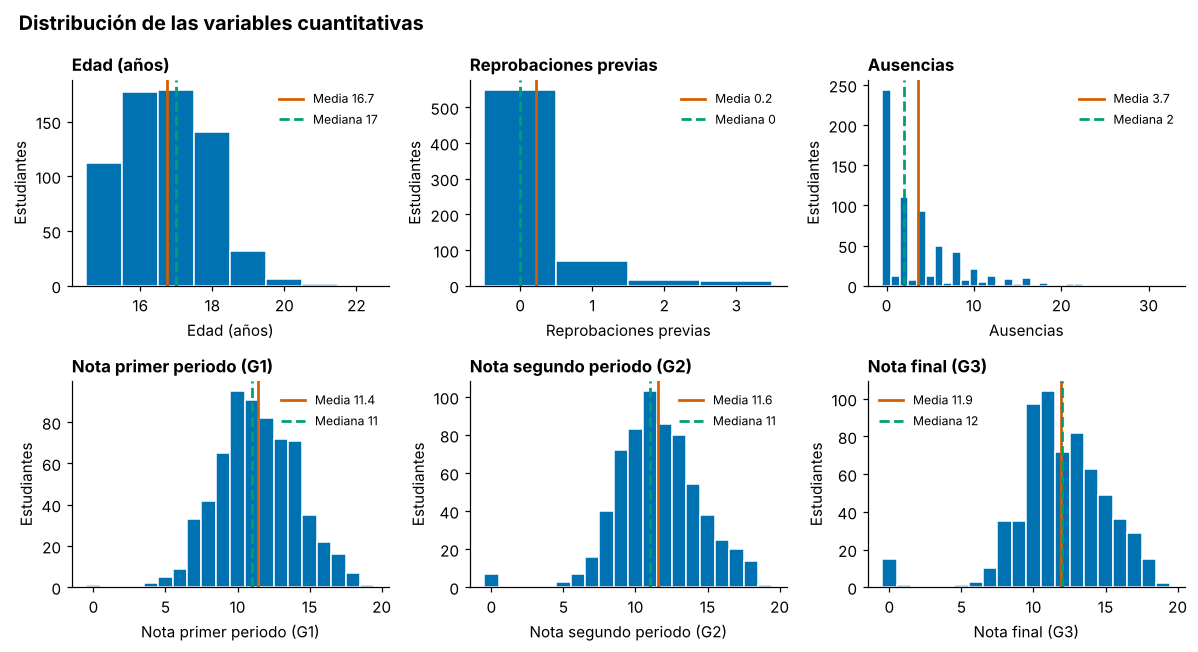

In [5]:
fig, ejes = plt.subplots(2, 3, figsize=(11, 6))
titulos = {"age": "Edad (años)", "failures": "Reprobaciones previas", "absences": "Ausencias",
           "G1": "Nota primer periodo (G1)", "G2": "Nota segundo periodo (G2)", "G3": "Nota final (G3)"}
for ax, v in zip(ejes.flat, cuant):
    s = df[v]
    ax.hist(s, bins=np.arange(s.min() - 0.5, s.max() + 1.5, 1), color=AZUL, edgecolor="white")
    ax.axvline(s.mean(), color=NARANJA, lw=1.8, label=f"Media {s.mean():.1f}")
    ax.axvline(s.median(), color=VERDE, lw=1.8, ls="--", label=f"Mediana {s.median():.0f}")
    ax.set_title(titulos[v]); ax.set_xlabel(titulos[v]); ax.set_ylabel("Estudiantes")
    ax.legend(fontsize=8)
fig.suptitle("Distribución de las variables cuantitativas", x=0.02, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

Figura 1. Histogramas de las variables cuantitativas, con la media (línea naranja) y la mediana (línea verde discontinua). Fuente: elaboración propia con datos de Cortez y Silva (2008).

Interpretación. Las tres notas tienen forma de campana con centro entre 11 y 12. En G3 se ve a la izquierda una barra aislada en 0 (15 estudiantes) separada del resto, porque la distribución solo se vuelve densa desde 6 o 7. Esa barra no parece una continuación natural de la distribución sino un grupo aparte, que se revisa en la sección 7.3. Las ausencias tienen una barra muy alta en 0 y una cola larga a la derecha, y las reprobaciones previas se concentran casi todas en 0. La edad se concentra entre los 15 y los 18 años (93,7 % de los estudiantes), con muy pocos casos de 20 años o más.

### 5.2 Distribución de frecuencias de la nota final

La nota final es la variable objetivo de la regresión, así que se le construye una tabla de frecuencias por intervalos. Con 649 datos, la regla de Sturges (1926) sugiere cerca de 11 clases ($k=1+\log_2 n$); como la nota va de 0 a 20 se usan intervalos de ancho 2, que son fáciles de leer.

In [6]:
lim = np.arange(0, 22, 2)
clases = pd.cut(df["G3"], bins=lim, right=False)
fi = clases.value_counts().sort_index()
tabla_g3 = pd.DataFrame({
    "Marca de clase": [(a.left + a.right) / 2 for a in fi.index],
    "Frecuencia absoluta (fi)": fi.values,
    "Frecuencia relativa (%)": (fi.values / fi.sum() * 100).round(2),
    "Frec. acumulada (Fi)": fi.cumsum().values,
    "Frec. relativa acumulada (%)": (fi.cumsum().values / fi.sum() * 100).round(2),
}, index=[f"[{int(a.left)}, {int(a.right)})" for a in fi.index])
tabla_g3.index.name = "Intervalo de G3"
print("Clases según Sturges:", int(np.ceil(1 + np.log2(len(df)))))
tabla_g3

Clases según Sturges: 11


,Marca de clase,Frecuencia absoluta (fi),Frecuencia relativa (%),Frec. acumulada (Fi),Frec. relativa acumulada (%)
Intervalo de G3,,,,,
"[0, 2)",1.0,16,2.47,16,2.47
"[2, 4)",3.0,0,0.00,16,2.47
"[4, 6)",5.0,1,0.15,17,2.62
"[6, 8)",7.0,13,2.00,30,4.62
"[8, 10)",9.0,70,10.79,100,15.41
"[10, 12)",11.0,201,30.97,301,46.38
"[12, 14)",13.0,154,23.73,455,70.11
"[14, 16)",15.0,112,17.26,567,87.37
"[16, 18)",17.0,65,10.02,632,97.38


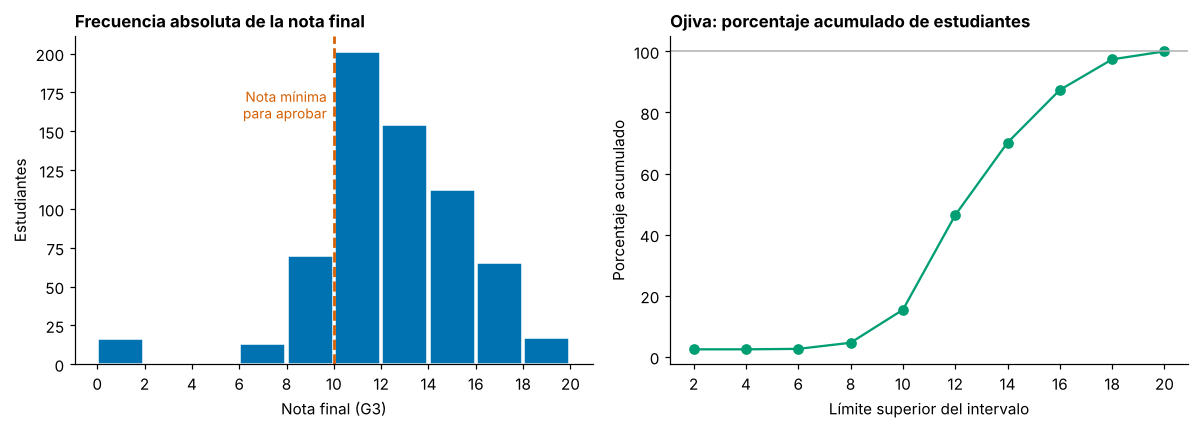

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.bar(tabla_g3["Marca de clase"], tabla_g3["Frecuencia absoluta (fi)"], width=1.9, color=AZUL, edgecolor="white")
ax1.axvline(10, color=NARANJA, lw=1.8, ls="--"); ax1.text(9.7, ax1.get_ylim()[1] * 0.75, "Nota mínima\npara aprobar", color=NARANJA, fontsize=9, ha="right")
ax1.set_title("Frecuencia absoluta de la nota final"); ax1.set_xlabel("Nota final (G3)"); ax1.set_ylabel("Estudiantes")
ax1.set_xticks(lim)
ax2.plot(lim[1:], tabla_g3["Frec. relativa acumulada (%)"].values, marker="o", color=VERDE)
ax2.axhline(100, color=GRIS, lw=1)
ax2.set_title("Ojiva: porcentaje acumulado de estudiantes"); ax2.set_xlabel("Límite superior del intervalo"); ax2.set_ylabel("Porcentaje acumulado")
ax2.set_xticks(lim[1:])
fig.tight_layout(); plt.show()

Tabla 4 y Figura 2. Distribución de frecuencias de la nota final (G3) y ojiva. Fuente: elaboración propia con datos de Cortez y Silva (2008).

Interpretación. El intervalo más frecuente es [10, 12), con 201 estudiantes (31,0 %). La frecuencia acumulada hasta la nota 10 es de 100 estudiantes (15,4 %), que corresponde exactamente a los reprobados, y el 46,4 % obtiene menos de 12. En la parte alta, solo 17 estudiantes (2,6 %) obtienen 18 o más y nadie llega a 20. Llama la atención el hueco entre 0 y 6: hay 16 estudiantes en [0, 2) (15 de ellos con cero), ninguno en [2, 4) y uno en [4, 6), lo que refuerza que los ceros son un grupo distinto de los estudiantes que simplemente tienen notas bajas.

### 5.3 Variables cualitativas

Para las diecisiete variables categóricas de texto se calculan las frecuencias absolutas y relativas.

In [8]:
partes = []
for v in nominales:
    f = df[v].value_counts()
    partes.append(pd.DataFrame({"Variable": v, "Categoría": f.index, "n": f.values, "%": (f.values / len(df) * 100).round(1)}))
tabla_cat = pd.concat(partes).set_index(["Variable", "Categoría"])
tabla_cat

n     %
Variable   Categoría            
school     GP          423  65.2
           MS          226  34.8
sex        F           383  59.0
           M           266  41.0
address    U           452  69.6
           R           197  30.4
famsize    GT3         457  70.4
           LE3         192  29.6
Pstatus    T           569  87.7
           A            80  12.3
Mjob       other       258  39.8
           services    136  21.0
           at_home     135  20.8
           teacher      72  11.1
           health       48   7.4
Fjob       other       367  56.5
           services    181  27.9
           at_home      42   6.5
           teacher      36   5.5
           health       23   3.5
reason     course      285  43.9
           home        149  23.0
           reputation  143  22.0
           other        72  11.1
guardian   mother      455  70.1
           father      153  23.6
           other        41   6.3
schoolsup  no          581  89.5
           yes          68  10.5
famsup     yes         398  61.3
           no          251  38.7
paid       no          610  94.0
           yes          39   6.0
activities no          334  51.5
           yes         315  48.5
nursery    yes         521  80.3
           no          128  19.7
higher     yes         580  89.4
           no           69  10.6
internet   yes         498  76.7
           no          151  23.3
romantic   no          410  63.2
           yes         239  36.8

Tabla 5. Frecuencias de las variables categóricas. Fuente: elaboración propia con datos de Cortez y Silva (2008).

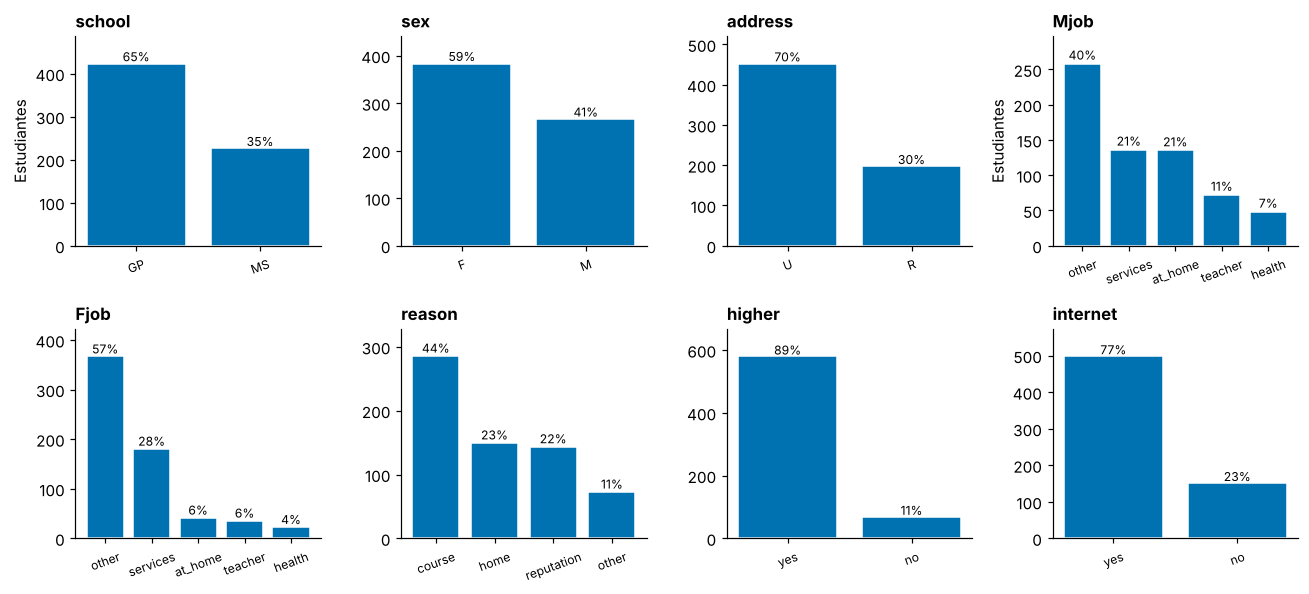

In [9]:
sel = ["school", "sex", "address", "Mjob", "Fjob", "reason", "higher", "internet"]
fig, ejes = plt.subplots(2, 4, figsize=(12, 5.5))
for ax, v in zip(ejes.flat, sel):
    f = df[v].value_counts()
    ax.bar(f.index, f.values, color=AZUL, edgecolor="white")
    for x, y in zip(range(len(f)), f.values):
        ax.text(x, y + 6, f"{y / len(df) * 100:.0f}%", ha="center", fontsize=8)
    ax.set_title(v); ax.set_ylim(0, f.max() * 1.15)
    ax.tick_params(axis="x", labelsize=8, rotation=20)
    if v in ("school", "Mjob"): ax.set_ylabel("Estudiantes")
fig.tight_layout(); plt.show()

Figura 3. Distribución de ocho variables categóricas seleccionadas. Fuente: elaboración propia con datos de Cortez y Silva (2008).

Interpretación. Predominan los estudiantes de la escuela GP (65,2 %), las mujeres (59,0 %) y la zona urbana (69,6 %). La gran mayoría quiere cursar educación superior (89,4 %) y tiene internet en casa (76,7 %). En la ocupación de los padres domina la categoría other (39,8 % en madres y 56,5 % en padres) y categorías como teacher o health son pequeñas, lo que luego produce frecuencias esperadas bajas en las pruebas chi cuadrado. Algunas variables binarias están muy desbalanceadas, como paid (94,0 % responde no) y schoolsup (89,5 % responde no), así que aportan poca variación para distinguir estudiantes.

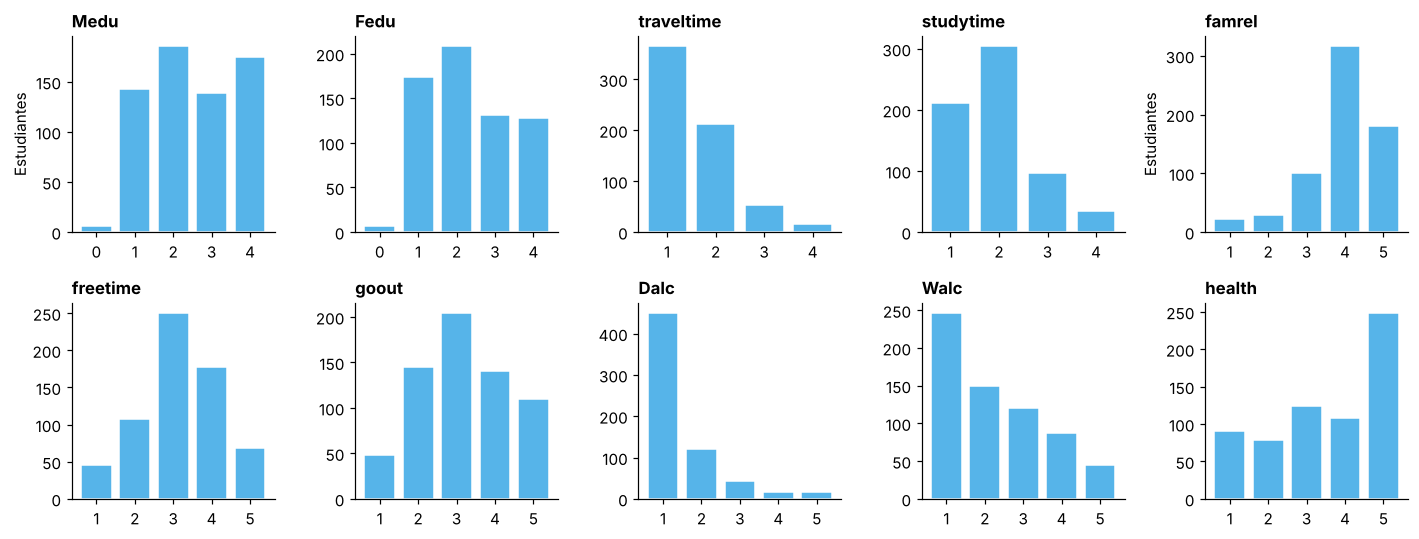

In [10]:
fig, ejes = plt.subplots(2, 5, figsize=(13, 5))
for ax, v in zip(ejes.flat, ordinales):
    f = df[v].value_counts().sort_index()
    ax.bar(f.index.astype(str), f.values, color=CELESTE, edgecolor="white")
    ax.set_title(v)
    if v in ("Medu", "famrel"): ax.set_ylabel("Estudiantes")
fig.tight_layout(); plt.show()

Figura 4. Distribución de las variables ordinales (escalas de 1 a 5 y niveles ordenados). Fuente: elaboración propia con datos de Cortez y Silva (2008).

Interpretación. El consumo de alcohol entre semana es bajo para casi todos (69 % en el nivel 1), mientras que el de fin de semana está más repartido (38 % en el nivel 1 y 20 % en los niveles 4 y 5). Los estudiantes dedican poco tiempo de estudio: el 80 % estudia menos de cinco horas semanales. Las relaciones familiares son en general buenas (77 % en los niveles 4 y 5) y la salud se reporta alta en su mayoría (38 % en el nivel 5), aunque con una cola de 14 % en el nivel 1. En la educación de los padres muy pocos tienen nivel 0 (1 %), un dato a tener presente al codificar porque esa categoría tiene casi ningún caso.

### 5.4 Viabilidad de los tres tipos de objetivos

Como la guía exige que el conjunto permita regresión, clasificación y segmentación, se hace una verificación visual rápida. A la izquierda se muestra la variable de clasificación (aprobado o reprobado). A la derecha se proyectan los estudiantes sobre las dos primeras componentes principales de las variables de hábitos y contexto (edad, reprobaciones, ausencias y las diez ordinales, estandarizadas), sin incluir las notas, para ver si hay estructura que se pueda agrupar.

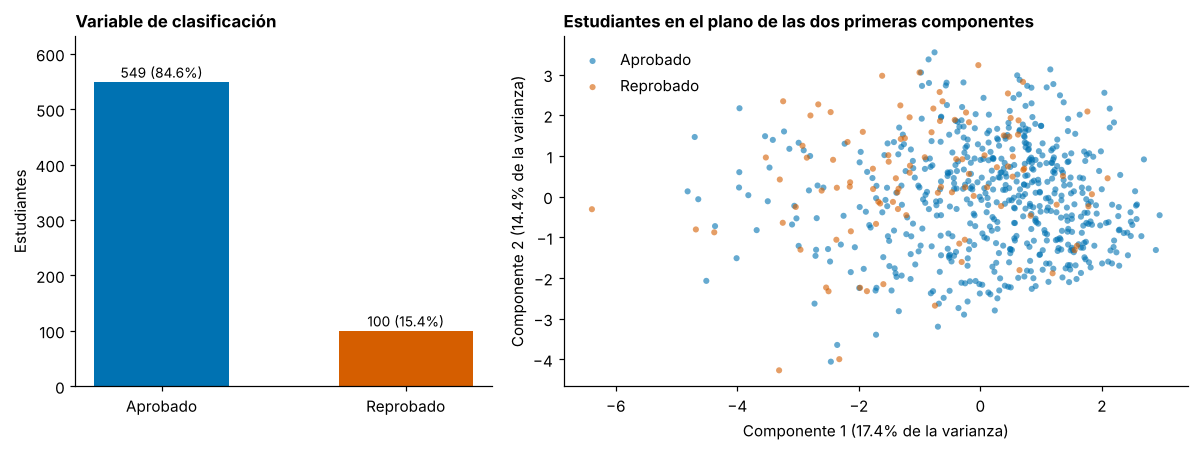

Varianza explicada por las dos primeras componentes: 31.8%


In [11]:
vars_perfil = ["age", "failures", "absences"] + ordinales
Z = (df[vars_perfil] - df[vars_perfil].mean()) / df[vars_perfil].std()
U, S, Vt = np.linalg.svd(Z.values, full_matrices=False)
pcs = U[:, :2] * S[:2]
var_exp = S ** 2 / np.sum(S ** 2)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1, 1.5]})
cnt = df["estado"].value_counts().reindex(["Aprobado", "Reprobado"])
ax1.bar(cnt.index, cnt.values, color=[AZUL, NARANJA], width=0.55)
for i, v in enumerate(cnt.values):
    ax1.text(i, v + 8, f"{v} ({v / len(df) * 100:.1f}%)", ha="center", fontsize=9)
ax1.set_ylim(0, cnt.max() * 1.15); ax1.set_title("Variable de clasificación"); ax1.set_ylabel("Estudiantes")

for est, col in [("Aprobado", AZUL), ("Reprobado", NARANJA)]:
    m = (df["estado"] == est).values
    ax2.scatter(pcs[m, 0], pcs[m, 1], s=16, alpha=0.6, color=col, label=est, edgecolor="none")
ax2.set_xlabel(f"Componente 1 ({var_exp[0] * 100:.1f}% de la varianza)")
ax2.set_ylabel(f"Componente 2 ({var_exp[1] * 100:.1f}% de la varianza)")
ax2.set_title("Estudiantes en el plano de las dos primeras componentes"); ax2.legend()
fig.tight_layout(); plt.show()
print("Varianza explicada por las dos primeras componentes: %.1f%%" % (var_exp[:2].sum() * 100))

Figura 5. Variable de clasificación y proyección por componentes principales de las variables de hábitos y contexto. Fuente: elaboración propia con datos de Cortez y Silva (2008).

Interpretación. Aprobaron 549 estudiantes (84,6 %) y reprobaron 100 (15,4 %). La clase minoritaria es pequeña pero tiene suficientes casos para entrenar, aunque habrá que usar una partición estratificada y considerar pesos de clase o SMOTE en la Fase 2. En la proyección, las dos primeras componentes recogen solo el 31,8 % de la varianza (17,4 % y 14,4 %), así que el plano pierde bastante información. La nube de puntos es una sola masa continua, sin grupos separados a simple vista. Los reprobados aparecen mezclados con los aprobados, aunque se concentran un poco más hacia la izquierda de la primera componente, lo que indica que las variables de hábitos y contexto contienen algo de señal sobre el riesgo, pero no la suficiente para separar las clases por sí solas. Para la segmentación esto sugiere que se encontrarán perfiles graduales más que grupos nítidos, cuya calidad se evaluará con la silueta. En conjunto, el conjunto de datos sirve para los tres objetivos: G3 para la regresión, aprobado para la clasificación y las variables de hábitos para el agrupamiento.

## 6. Análisis bivariado y multivariado

### 6.1 Correlación de Spearman

Se calcula la matriz de correlación de Spearman entre las 16 variables numéricas del archivo original. Se eligió Spearman y no Pearson porque buena parte de las variables son escalas ordinales y varias distribuciones están sesgadas.

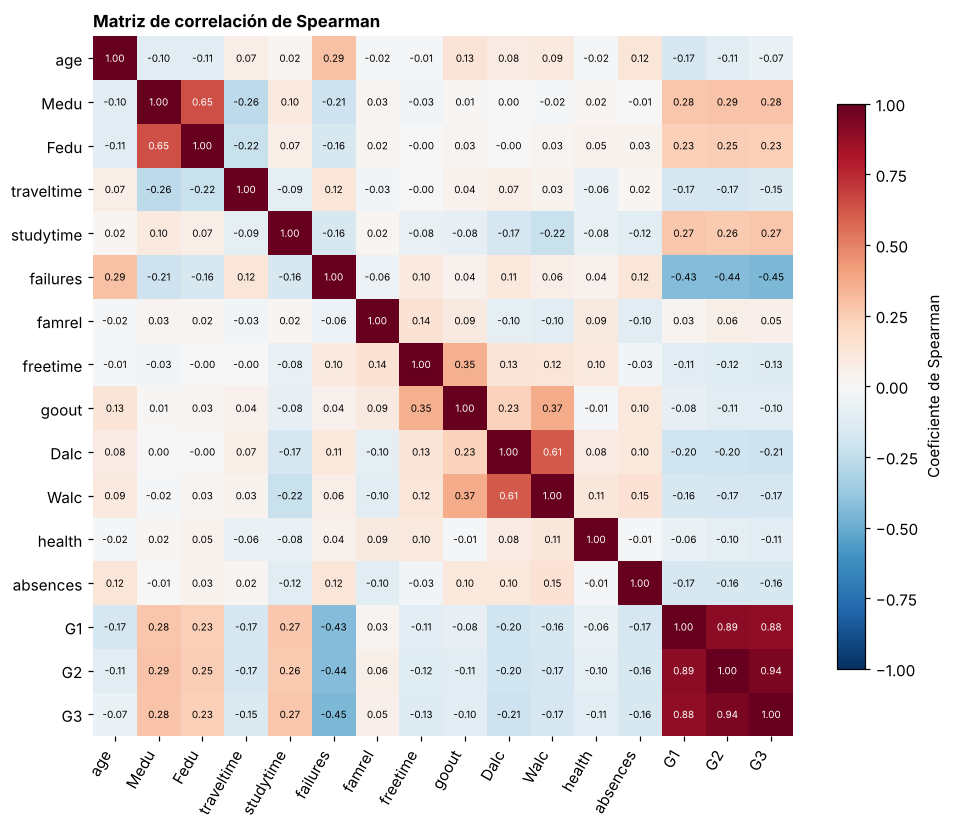

In [12]:
num = df.select_dtypes(include="number").columns.drop(["aprobado"]).tolist()
corr = df[num].corr(method="spearman")

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(num))); ax.set_xticklabels(num, rotation=60, ha="right")
ax.set_yticks(range(len(num))); ax.set_yticklabels(num)
for i in range(len(num)):
    for j in range(len(num)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=6.5,
                color="white" if abs(corr.values[i, j]) > 0.55 else "black")
for s in ax.spines.values(): s.set_visible(False)
cb = fig.colorbar(im, ax=ax, shrink=0.8); cb.set_label("Coeficiente de Spearman")
ax.set_title("Matriz de correlación de Spearman")
fig.tight_layout(); plt.show()

Figura 6. Matriz de correlación de Spearman entre las variables numéricas. Fuente: elaboración propia con datos de Cortez y Silva (2008).

In [13]:
filas = []
for v in num:
    if v == "G3": continue
    rho, p = stats.spearmanr(df[v], df["G3"])
    filas.append({"Variable": v, "rho con G3": rho, "Valor p": p})
tabla_corr = pd.DataFrame(filas).set_index("Variable")
tabla_corr = tabla_corr.reindex(tabla_corr["rho con G3"].abs().sort_values(ascending=False).index)
tabla_corr["rho con G3"] = tabla_corr["rho con G3"].round(3)
tabla_corr["Valor p"] = tabla_corr["Valor p"].map(lambda x: f"{x:.2e}")
tabla_corr

,rho con G3,Valor p
Variable,,
G2,0.944,0.00e+00
G1,0.883,4.99e-215
failures,-0.448,2.05e-33
Medu,0.284,1.69e-13
studytime,0.275,1.06e-12
Fedu,0.235,1.44e-09
Dalc,-0.208,8.43e-08
Walc,-0.171,1.20e-05
absences,-0.159,4.99e-05


Tabla 6. Correlación de Spearman de cada variable numérica con la nota final, ordenada por magnitud. Fuente: elaboración propia con datos de Cortez y Silva (2008).

Interpretación. Las notas parciales dominan: G2 (rho = 0,944) y G1 (0,883) tienen una correlación muy alta con G3. Después, con magnitud moderada, aparecen las reprobaciones previas (-0,448), la educación de la madre (0,284) y el tiempo de estudio (0,275). El consumo de alcohol entre semana (-0,208) y de fin de semana (-0,171), las ausencias (-0,159) y el tiempo de viaje (-0,147) tienen una correlación débil y negativa. La edad y la calidad de las relaciones familiares no resultan significativas al 5 % (valores p de 0,092 y 0,224). En la matriz de la Figura 6 también se ve que G1, G2 y G3 forman un bloque muy correlacionado, y que la educación de la madre y del padre, así como el alcohol entre semana y el de fin de semana, se mueven juntas (rho de 0,65 entre Medu y Fedu, y de 0,61 entre Dalc y Walc). Dos precauciones. Primero, la correlación de G2 con G3 es tan alta que un modelo que la use casi copiará la nota, por lo que conviene comparar modelos con y sin G1 y G2. Segundo, con 649 casos una correlación pequeña puede ser estadísticamente significativa sin tener relevancia práctica.

### 6.2 Relaciones de la nota final con variables seleccionadas

Para ver la forma de las relaciones y no solo el coeficiente, se grafican cuatro casos: la nota del segundo periodo, las ausencias, las reprobaciones previas y el tiempo de estudio.

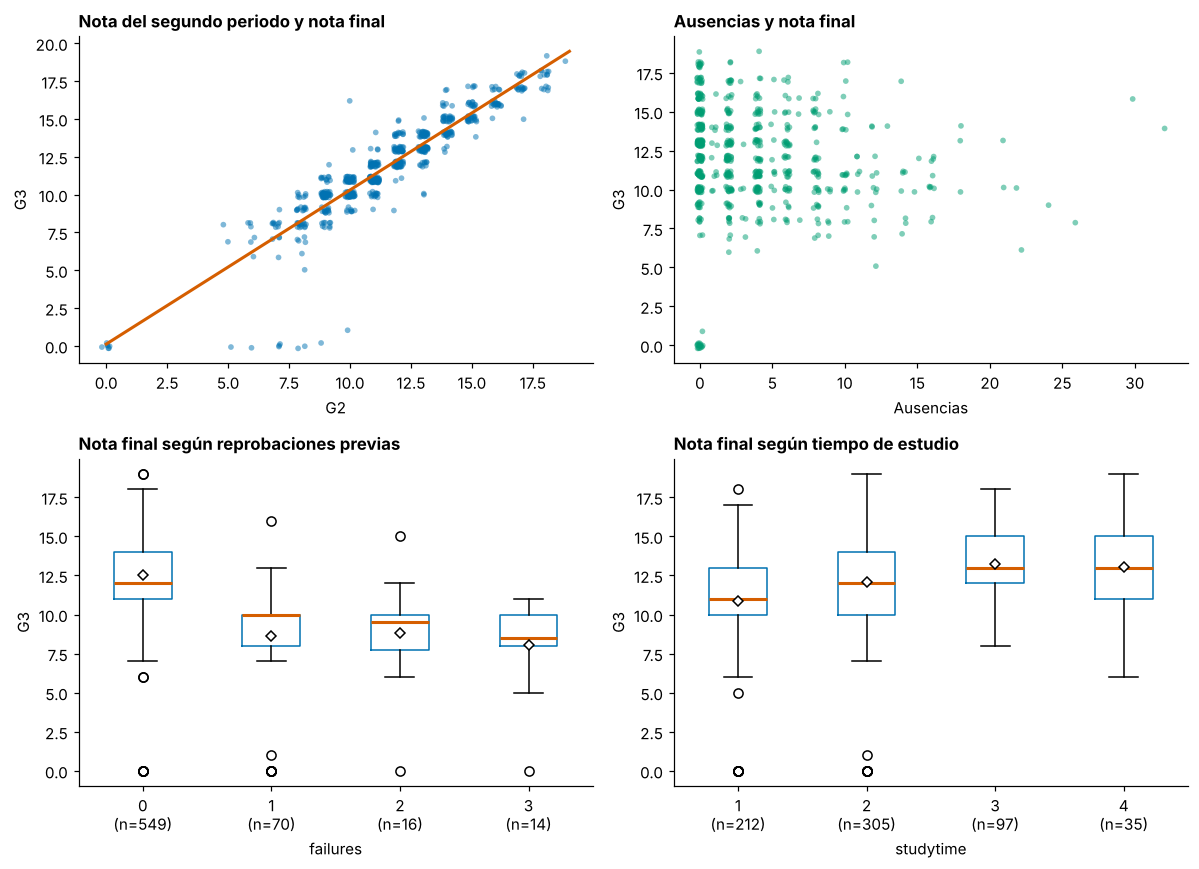

In [14]:
rng = np.random.default_rng(42)
fig, ejes = plt.subplots(2, 2, figsize=(11, 8))

ax = ejes[0, 0]
x, y = df["G2"], df["G3"]
ax.scatter(x + rng.uniform(-.2, .2, len(df)), y + rng.uniform(-.2, .2, len(df)), s=14, alpha=.5, color=AZUL, edgecolor="none")
m, b = np.polyfit(x, y, 1); xs = np.array([x.min(), x.max()])
ax.plot(xs, m * xs + b, color=NARANJA, lw=2)
ax.set_title("Nota del segundo periodo y nota final"); ax.set_xlabel("G2"); ax.set_ylabel("G3")

ax = ejes[0, 1]
ax.scatter(df["absences"] + rng.uniform(-.2, .2, len(df)), y + rng.uniform(-.2, .2, len(df)), s=14, alpha=.5, color=VERDE, edgecolor="none")
ax.set_title("Ausencias y nota final"); ax.set_xlabel("Ausencias"); ax.set_ylabel("G3")

for ax, v, tit in [(ejes[1, 0], "failures", "Nota final según reprobaciones previas"), (ejes[1, 1], "studytime", "Nota final según tiempo de estudio")]:
    niv = sorted(df[v].unique())
    ax.boxplot([df.loc[df[v] == k, "G3"] for k in niv], showmeans=True,
               boxprops=dict(color=AZUL), medianprops=dict(color=NARANJA, lw=2),
               meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor="black", markersize=5))
    ax.set_xticks(range(1, len(niv) + 1)); ax.set_xticklabels([f"{k}\n(n={int((df[v] == k).sum())})" for k in niv])
    ax.set_title(tit); ax.set_xlabel(v); ax.set_ylabel("G3")
fig.tight_layout(); plt.show()

Figura 7. Relaciones entre la nota final y cuatro variables. En los diagramas de dispersión se añadió una pequeña dispersión aleatoria (jitter) para evitar que los puntos se superpongan; en los diagramas de caja el rombo es la media. Fuente: elaboración propia con datos de Cortez y Silva (2008).

Interpretación. La relación entre G2 y G3 es casi una recta: la regresión simple da una pendiente de 1,02 y un R² de 0,84, es decir que G2 por sí sola explica el 84 % de la variación de G3. Los puntos que quedan muy por debajo de la recta son los estudiantes con G3 = 0. Con las ausencias no hay una relación clara: la nube es ancha y casi plana, algo coherente con el coeficiente de -0,159, y llama la atención que los 15 ceros están todos en la columna de cero ausencias. En las reprobaciones previas hay un salto marcado: la media de G3 es 12,51 sin reprobaciones, 8,64 con una, 8,81 con dos y 8,07 con tres, así que una sola reprobación previa ya se asocia con unos cuatro puntos menos (los grupos de dos y tres reprobaciones son pequeños, con 16 y 14 estudiantes). En el tiempo de estudio la media sube de 10,84 (menos de 2 horas) a 12,09, 13,23 y 13,06 en los niveles 2, 3 y 4, y la mejora parece estabilizarse después de cinco horas, aunque el nivel 4 solo tiene 35 estudiantes.

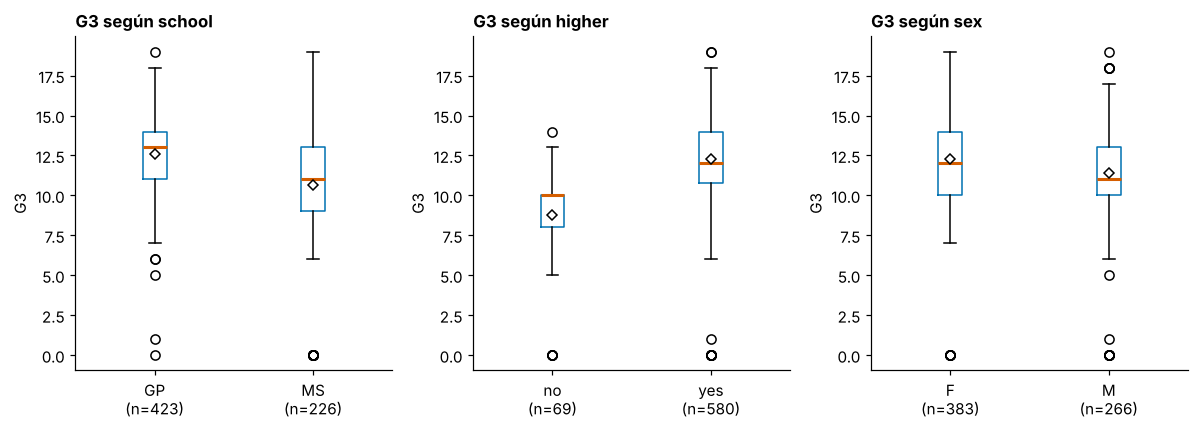

In [15]:
fig, ejes = plt.subplots(1, 3, figsize=(11, 4))
for ax, v in zip(ejes, ["school", "higher", "sex"]):
    niv = sorted(df[v].unique())
    ax.boxplot([df.loc[df[v] == k, "G3"] for k in niv], showmeans=True,
               boxprops=dict(color=AZUL), medianprops=dict(color=NARANJA, lw=2),
               meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor="black", markersize=5))
    ax.set_xticks(range(1, len(niv) + 1)); ax.set_xticklabels([f"{k}\n(n={int((df[v] == k).sum())})" for k in niv])
    ax.set_title(f"G3 según {v}"); ax.set_ylabel("G3")
fig.tight_layout(); plt.show()

Figura 8. Nota final según escuela, deseo de cursar educación superior y sexo. Fuente: elaboración propia con datos de Cortez y Silva (2008).

Interpretación. La escuela GP tiene una mediana de 13 y una media de 12,58, frente a una mediana de 11 y una media de 10,65 en MS, y la tasa de aprobación es de 92,4 % en GP y 69,9 % en MS. Quienes quieren cursar educación superior tienen una media de 12,28 frente a 8,80 de quienes no (medianas de 12 y 10) y una aprobación de 88,4 % frente a 52,2 %. Por sexo, las mujeres tienen una media de 12,25 y los hombres de 11,41, una diferencia menor. Hay que tener cuidado con los tamaños desiguales (580 estudiantes con deseo de estudios superiores frente a 69 sin él) y con no leer estas diferencias como causas: que MS tenga peores resultados puede reflejar el contexto de sus estudiantes y, como se ve en la sección 7.3, 14 de los 15 ceros están en esa escuela.

### 6.3 Pruebas de independencia chi cuadrado

Se prueba si cada variable categórica de texto es independiente de la aprobación. La hipótesis nula es que no hay asociación. Como son 17 pruebas simultáneas, se agrega una corrección de Bonferroni (nivel 0,05/17, cerca de 0,0029) para no sobreinterpretar un valor p pequeño que aparezca por azar. No se aplica la corrección de Yates en las tablas 2x2 para que el chi cuadrado sea coherente con la V de Cramér, y se reporta la frecuencia esperada mínima porque la prueba pierde fiabilidad cuando es menor que 5.

In [16]:
filas = []
for v in nominales:
    tab = pd.crosstab(df[v], df["aprobado"])
    chi2, p, gl, esp = stats.chi2_contingency(tab, correction=False)
    V = np.sqrt(chi2 / (len(df) * (min(tab.shape) - 1)))
    filas.append({"Variable": v, "Chi2": chi2, "gl": gl, "Valor p": p, "V de Cramér": V,
                  "Frec. esperada mínima": esp.min(), "Significativa (Bonferroni)": "Sí" if p < 0.05 / len(nominales) else "No"})
tabla_chi = pd.DataFrame(filas).set_index("Variable").sort_values("V de Cramér", ascending=False)
t = tabla_chi.copy()
t["Chi2"] = t["Chi2"].round(2); t["V de Cramér"] = t["V de Cramér"].round(3)
t["Frec. esperada mínima"] = t["Frec. esperada mínima"].round(1); t["Valor p"] = t["Valor p"].map(lambda x: f"{x:.2e}")
t

,Chi2,gl,Valor p,V de Cramér,Frec. esperada mínima,Significativa (Bonferroni)
Variable,,,,,,
higher,62.25,1,3.02e-15,0.310,10.6,Sí
school,57.33,1,3.68e-14,0.297,34.8,Sí
reason,17.99,3,4.42e-04,0.166,11.1,Sí
address,10.41,1,1.25e-03,0.127,30.4,Sí
Mjob,9.86,4,4.29e-02,0.123,7.4,No
internet,5.05,1,2.46e-02,0.088,23.3,No
guardian,4.63,2,9.89e-02,0.084,6.3,No
romantic,4.28,1,3.86e-02,0.081,36.8,No
sex,3.97,1,4.63e-02,0.078,41.0,No


Tabla 7. Pruebas de independencia chi cuadrado entre cada variable categórica y la aprobación, ordenadas por la V de Cramér. Fuente: elaboración propia con datos de Cortez y Silva (2008).

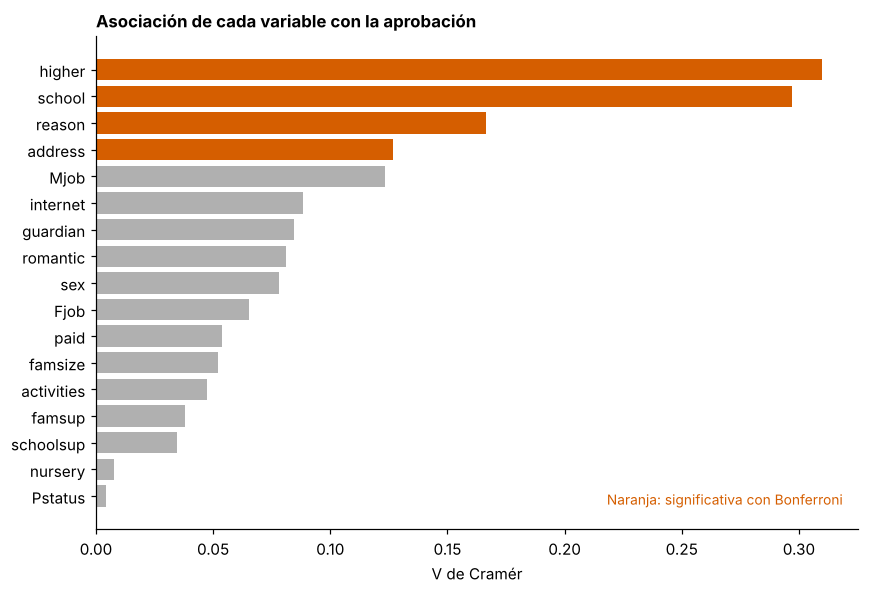

In [17]:
o = tabla_chi.sort_values("V de Cramér")
colores = [NARANJA if s == "Sí" else GRIS for s in o["Significativa (Bonferroni)"]]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(o.index, o["V de Cramér"], color=colores)
ax.set_xlabel("V de Cramér"); ax.set_title("Asociación de cada variable con la aprobación")
ax.text(0.98, 0.05, "Naranja: significativa con Bonferroni", transform=ax.transAxes, ha="right", color=NARANJA, fontsize=9)
fig.tight_layout(); plt.show()

Figura 9. Intensidad de la asociación (V de Cramér) entre las variables categóricas y la aprobación. Fuente: elaboración propia con datos de Cortez y Silva (2008).

Interpretación. Con la corrección de Bonferroni, cuatro variables se asocian de forma significativa con la aprobación: higher (V = 0,310), school (0,297), reason (0,166) y address (0,127). Las dos primeras tienen una asociación moderada y las otras dos débil. En address, por ejemplo, aprueba el 87,6 % de la zona urbana y el 77,7 % de la rural. Mjob, internet, romantic y sex tienen un valor p menor que 0,05, pero no resisten la corrección, así que se toman como indicios y no como resultados firmes. El resto no muestra evidencia de asociación, con V cercana a cero en Pstatus y nursery. Como advertencia, solo en Fjob la frecuencia esperada mínima baja de 5 (3,5), por lo que ese resultado debe tomarse con más cuidado.

## 7. Diagnóstico de calidad de datos

### 7.1 Datos faltantes, valores fuera de rango y duplicados

In [18]:
falt = pd.DataFrame({"Faltantes": df.isna().sum(), "% faltantes": (df.isna().mean() * 100).round(2)})
falt = falt.drop(index=["aprobado", "estado"])
print("Total de celdas vacías:", int(df.isna().sum().sum()))
print("Variables con algún faltante:", int((falt["Faltantes"] > 0).sum()))

# Marcadores de faltante escondidos como texto
marcas = {"", " ", "?", "NA", "N/A", "na", "null", "NULL", "-", "nan"}
ocultos = {v: int(df[v].isin(marcas).sum()) for v in nominales if df[v].isin(marcas).any()}
print("Marcadores de faltante escondidos en texto:", ocultos if ocultos else "ninguno")

# Valores fuera del rango definido en el diccionario
reglas = {"age": (15, 22), "Medu": (0, 4), "Fedu": (0, 4), "traveltime": (1, 4), "studytime": (1, 4), "failures": (0, 4),
          "famrel": (1, 5), "freetime": (1, 5), "goout": (1, 5), "Dalc": (1, 5), "Walc": (1, 5), "health": (1, 5),
          "absences": (0, 93), "G1": (0, 20), "G2": (0, 20), "G3": (0, 20)}
fuera = {v: int(((df[v] < a) | (df[v] > b)).sum()) for v, (a, b) in reglas.items()}
print("Valores fuera de rango:", {k: n for k, n in fuera.items() if n} or "ninguno")
print("Filas duplicadas exactas:", int(df.drop(columns=["aprobado", "estado"]).duplicated().sum()))
falt.T

Total de celdas vacías: 0
Variables con algún faltante: 0
Marcadores de faltante escondidos en texto: ninguno
Valores fuera de rango: ninguno
Filas duplicadas exactas: 0


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
Faltantes,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
% faltantes,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Tabla 8. Porcentaje de datos faltantes por variable. Fuente: elaboración propia con datos de Cortez y Silva (2008).

Interpretación. El conjunto no tiene datos faltantes: 0 % en las 33 variables. Tampoco hay marcadores de faltante escondidos como texto (signos de interrogación, espacios o cadenas vacías), valores fuera de los rangos del diccionario ni filas duplicadas. Esto es coherente con un archivo que ya viene depurado por sus autores. Como consecuencia, el análisis del mecanismo de falta (MCAR, MAR o MNAR) que pide la guía para la Fase 2 no tiene mucho que decidir en sentido estricto. Sin embargo, hay un caso que merece atención, la nota final igual a cero (sección 7.3), que podría ser en la práctica un dato faltante registrado como cero. Además, la ausencia de duplicados exactos no garantiza que cada fila sea un estudiante distinto, porque el archivo no trae un identificador.

### 7.2 Valores atípicos

Se aplican las dos reglas pedidas en la guía, el RIC y el puntaje Z, a las seis variables cuantitativas.

In [19]:
def atipicos(s):
    q1, q3 = s.quantile([.25, .75]); ric = q3 - q1
    li, ls = q1 - 1.5 * ric, q3 + 1.5 * ric
    z = (s - s.mean()) / s.std()
    n_iqr = int(((s < li) | (s > ls)).sum())
    return pd.Series({"Límite inferior": li, "Límite superior": ls, "Atípicos (RIC)": n_iqr,
                      "% (RIC)": round(n_iqr / len(s) * 100, 2), "Atípicos (|Z| > 3)": int((z.abs() > 3).sum())})
tabla_out = df[cuant].apply(atipicos).T
for c in ["Atípicos (RIC)", "Atípicos (|Z| > 3)"]:
    tabla_out[c] = tabla_out[c].astype(int)
tabla_out

,Límite inferior,Límite superior,Atípicos (RIC),% (RIC),Atípicos (|Z| > 3)
age,13.0,21.0,1,0.15,3
failures,0.0,0.0,100,15.41,14
absences,-9.0,15.0,21,3.24,11
G1,5.5,17.5,16,2.47,1
G2,5.5,17.5,25,3.85,7
G3,4.0,20.0,16,2.47,16


Tabla 9. Valores atípicos por la regla del RIC y por puntaje Z. Fuente: elaboración propia con datos de Cortez y Silva (2008).

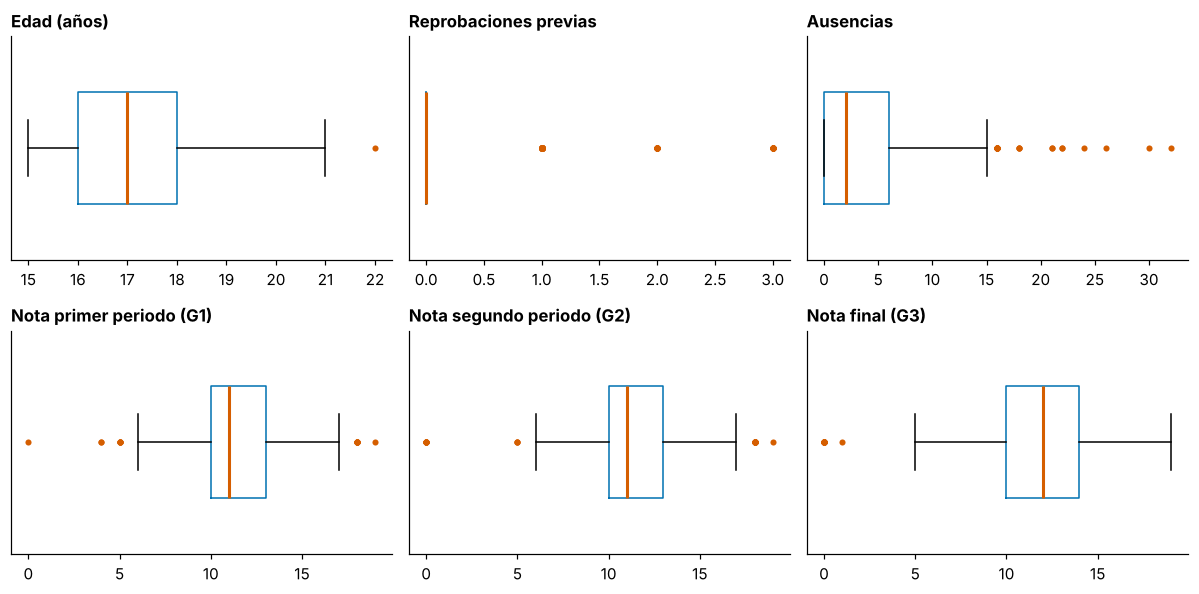

In [20]:
fig, ejes = plt.subplots(2, 3, figsize=(11, 5.5))
for ax, v in zip(ejes.flat, cuant):
    ax.boxplot(df[v], vert=False, widths=0.5, flierprops=dict(marker="o", markerfacecolor=NARANJA, markeredgecolor="none", markersize=4),
               boxprops=dict(color=AZUL), medianprops=dict(color=NARANJA, lw=2))
    ax.set_title(titulos[v]); ax.set_yticks([])
fig.tight_layout(); plt.show()

Figura 10. Diagramas de caja de las variables cuantitativas; los puntos naranja son los valores atípicos según la regla del RIC. Fuente: elaboración propia con datos de Cortez y Silva (2008).

Interpretación. La edad tiene 1 atípico por RIC y 3 por puntaje Z, que son los estudiantes de 21 y 22 años; son valores plausibles de rezago escolar y se conservarán. En las reprobaciones previas la regla del RIC no sirve: como Q1 y Q3 son ambos 0, cualquier valor mayor que 0 queda marcado y salen 100 estudiantes (15,4 %), que no son errores sino el grupo con antecedentes de reprobación (por puntaje Z solo salen 14). Las ausencias tienen 21 atípicos por RIC (más de 15 ausencias) y 11 por Z, con un máximo de 32, que son valores posibles; para la Fase 2 se evaluará una transformación logarítmica o un recorte por percentiles, por la cola larga. En las notas, G1 y G2 tienen 16 y 25 atípicos por RIC (límites de 5,5 y 17,5), y los 16 atípicos de G3 son los 15 ceros y una nota de 1. En ningún caso se trata de errores de captura evidentes; el único que se tratará aparte es el cero en G3.

### 7.3 Incoherencias

Además de los valores fuera de rango, se revisan combinaciones sospechosas entre variables. La más llamativa es una nota final de cero en estudiantes que sí tuvieron notas parciales positivas.

In [21]:
g3_cero = df[df["G3"] == 0]
print("Estudiantes con G3 = 0:", len(g3_cero))
print("  de ellos con G2 > 0:", int((g3_cero["G2"] > 0).sum()))
print("  de ellos con 0 ausencias:", int((g3_cero["absences"] == 0).sum()))
print("Estudiantes con caída de 5 o más puntos entre G2 y G3:", int(((df["G2"] - df["G3"]) >= 5).sum()))
print("Estudiantes con G1 = 0 o G2 = 0:", int(((df["G1"] == 0) | (df["G2"] == 0)).sum()))
g3_cero[["school", "sex", "age", "failures", "absences", "G1", "G2", "G3"]].reset_index(names="fila")

Estudiantes con G3 = 0: 15
  de ellos con G2 > 0: 8
  de ellos con 0 ausencias: 15
Estudiantes con caída de 5 o más puntos entre G2 y G3: 9
Estudiantes con G1 = 0 o G2 = 0: 8


,fila,school,sex,age,failures,absences,G1,G2,G3
0,163,GP,M,18,2,0,11,9,0
1,440,MS,M,16,0,0,7,0,0
2,519,MS,M,16,0,0,8,7,0
3,563,MS,M,17,1,0,7,0,0
4,567,MS,M,18,1,0,4,0,0
5,583,MS,F,18,1,0,8,6,0
6,586,MS,F,17,0,0,8,8,0
7,597,MS,F,18,1,0,9,0,0
8,603,MS,F,18,0,0,5,0,0
9,605,MS,F,19,1,0,5,0,0


Tabla 10. Estudiantes con nota final igual a cero. Fuente: elaboración propia con datos de Cortez y Silva (2008).

Interpretación. Hay 15 estudiantes con nota final igual a cero. De ellos, 14 pertenecen a la escuela MS (que tiene 226 estudiantes) y solo uno a GP. Los 15 tienen cero ausencias, siete también tienen G2 = 0 y los otros ocho tuvieron un G2 positivo, entre 5 y 9, lo que significa una caída de entre 5 y 9 puntos de un periodo al otro (ocho de los nueve estudiantes con caída de 5 o más puntos son estos mismos). Este patrón es más consistente con estudiantes que abandonaron o no se presentaron a la evaluación final que con un desempeño real de cero, y que no tengan ausencias registradas sugiere que ese dato tampoco se diligenció para ellos. Es una hipótesis: en la documentación consultada no se encontró una explicación. Lo importante es que esos 15 casos distorsionan la regresión (errores muy grandes sobre G3) y hacen que 15 de los 100 reprobados lo sean por una razón distinta a un bajo desempeño. En la Fase 2 se decidirá si se excluyen, se modelan con una variable indicadora o se tratan como un caso aparte, y se documentará el efecto de cada opción.

## 8. Conclusiones y hoja de ruta para las siguientes fases

El conjunto de datos de rendimiento en lengua portuguesa (649 estudiantes y 33 variables) cumple los requisitos de la guía: supera los 600 registros, mezcla variables cuantitativas y cualitativas, no tiene datos faltantes ni duplicados y permite plantear una regresión sobre la nota final (media de 11,91 y desviación de 3,23), una clasificación de aprobado o reprobado (84,6 % frente a 15,4 %) y una segmentación por hábitos y contexto.

Frente a las preguntas secundarias, el análisis exploratorio deja las siguientes respuestas preliminares. Sobre las variables más asociadas con el desempeño, las notas parciales G1 y G2 son por mucho las más fuertes (rho de 0,88 y 0,94), seguidas, con intensidad moderada, por las reprobaciones previas, el deseo de cursar educación superior, la escuela, el nivel educativo de la madre y el tiempo de estudio. Sobre el aporte de G1 y G2, por sí sola G2 explica el 84 % de la variación de G3, de modo que el modelo con esas variables será bueno pero poco útil para intervenir temprano; por eso se compararán versiones con y sin ellas. Sobre los perfiles, la proyección por componentes principales no muestra grupos separados, por lo que se espera encontrar perfiles graduales y se juzgará su calidad con el coeficiente de silueta.

Decisiones para la Fase 2 a partir de lo observado:

1. Nota final igual a cero: tratar los 15 casos de forma explícita (excluir, marcar con una variable indicadora o analizar aparte), comparando el efecto en las métricas.
2. Valores atípicos: conservar la edad, aplicar logaritmo o recorte por percentiles a las ausencias y no usar la regla del RIC en las reprobaciones previas.
3. Variables derivadas: se proponen el consumo total de alcohol (Dalc más Walc), el nivel educativo promedio de los padres y un indicador de reprobaciones previas, además de las ausencias en escala logarítmica.
4. Partición y desbalance: división estratificada por aprobado (por ejemplo 70 % entrenamiento, 15 % validación y 15 % prueba) y manejo del 15,4 % de reprobados con pesos de clase o SMOTE aplicado solo al conjunto de entrenamiento.
5. Codificación y escalamiento: codificación one-hot de las categóricas nominales y escalamiento ajustado solo con el conjunto de entrenamiento, para evitar fuga de datos.
6. Modelo base: un modelo de media (o regresión lineal simple de G3 sobre G2) para la regresión y un clasificador de referencia para la aprobación.

Quedan algunas limitaciones que se deben tener presentes. Los datos provienen de dos escuelas de Portugal, por lo que los resultados no se pueden generalizar sin cuidado, varias variables son escalas autorreportadas (como el consumo de alcohol) y las asociaciones encontradas no son causales. Además, el conjunto no tiene una variable de fecha, mientras que la guía menciona filtros por rangos de fechas en el dashboard; en la Fase 4 se usarán filtros por rangos de edad, ausencias y notas, y por categorías, y conviene confirmar este punto con el docente.

## 9. Referencias

Anscombe, F. J. (1973). Graphs in statistical analysis. The American Statistician, 27(1), 17-21.

Cleveland, W. S., y McGill, R. (1984). Graphical perception: Theory, experimentation, and application to the development of graphical methods. Journal of the American Statistical Association, 79(387), 531-554.

Cortez, P. (2008). Student Performance [Conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C5TG7T

Cortez, P., y Silva, A. (2008). Using data mining to predict secondary school student performance. En A. Brito y J. Teixeira (Eds.), Proceedings of 5th FUture BUsiness TEChnology Conference (FUBUTEC 2008) (pp. 5-12). EUROSIS.

Cramér, H. (1946). Mathematical methods of statistics. Princeton University Press.

Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. Computing in Science & Engineering, 9(3), 90-95. https://doi.org/10.1109/MCSE.2007.55

Knaflic, C. N. (2015). Storytelling with data: A data visualization guide for business professionals. Wiley.

McKinney, W. (2010). Data structures for statistical computing in Python. Proceedings of the 9th Python in Science Conference, 56-61.

Okabe, M., e Ito, K. (2008). Color Universal Design (CUD): How to make figures and presentations that are friendly to colorblind people. https://jfly.uni-koeln.de/color/

Sturges, H. A. (1926). The choice of a class interval. Journal of the American Statistical Association, 21(153), 65-66.

Tukey, J. W. (1977). Exploratory data analysis. Addison-Wesley.

Virtanen, P., Gommers, R., Oliphant, T. E., et al. (2020). SciPy 1.0: Fundamental algorithms for scientific computing in Python. Nature Methods, 17, 261-272. https://doi.org/10.1038/s41592-019-0686-2

Wilke, C. O. (2019). Fundamentals of data visualization. O'Reilly Media.